# ML Assignment 02

### Dataset: House Price Prediction Dataset

### Total Marks: 100

---

## Exam Instructions:

1. প্রথমে নিচের cell এ নিজের **নাম** এবং কোর্সে registration করা **ইমেইল** দিবে
2. Question wise numbering করে Text cell রাখবে এবং এর নিচে Code cell থাকবে, চেষ্টা করবে একটি code cell এ একটি question উত্তর দেওয়ার
3. Google Colab এর মধ্যে কোডগুলো করবে
4. এবং সেই ফাইলটি **'Anyone with the link' & 'View' Access** দিয়ে ফাইলটির Shareable Link টি সাবমিট করবে

---

**Question Dataset Link:** https://www.kaggle.com/datasets/prokshitha/home-value-insights


## Student Information


In [11]:
# Fill in your information
name = "Rafiur Rahman Saikat"  # Write your full name here
email = "md.rafiur.rahman.saikat@gmail.com"  # Write your registered email here

print(f"Name  : {name}")
print(f"Email : {email}")

Name  : Rafiur Rahman Saikat
Email : md.rafiur.rahman.saikat@gmail.com


---

## Question 1 (10 Marks)

Load the House Price dataset and display:

- Dataset shape
- First 10 rows
- 5 random samples


In [ ]:
# Question 1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style="darkgrid")

df = pd.read_csv("house_price_regression_dataset.csv")

df.shape
df.head(10)
df.sample(5)

display(df.shape, df.head(10), df.sample(5))

(1000, 8)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
5,3944,5,3,1990,2.475930,2,8,8.797970e+05
6,3671,1,2,2012,4.911960,0,1,8.144279e+05
7,3419,1,1,1972,2.805281,1,1,7.034131e+05
8,630,3,3,1997,1.014286,1,8,1.738750e+05
9,2185,4,2,1981,3.941604,2,5,5.041765e+05


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
398,3274,4,1,2004,2.808150,1,3,7.248422e+05
48,534,3,1,2016,2.527154,0,10,1.875086e+05
315,3160,3,2,1974,1.358267,0,6,6.453752e+05
552,4985,1,2,1990,1.608099,1,5,1.032002e+06
844,2334,5,1,1966,2.351186,2,7,5.153006e+05


---

## Question 2 (10 Marks)

Handle missing values and perform feature engineering:

- Impute missing numerical values using `SimpleImputer` with mean strategy
- Impute missing categorical values using most frequent strategy
- Drop columns with more than 50% missing values
- Perform train-test split with `test_size=0.2` and `random_state=42`

Display the shape of final train and test sets.


## Basic Analysis


Square_Footage: 0 outliers found (Bounds: -1400.5 to 6999.5)
Lot_Size: 0 outliers found (Bounds: -1.720111744921275 to 7.309374907222705)
House_Price: 0 outliers found (Bounds: -236591.34418214735 to 1465380.8507282762)
Year_Built: 0 outliers found (Bounds: 1916.125 to 2057.125)


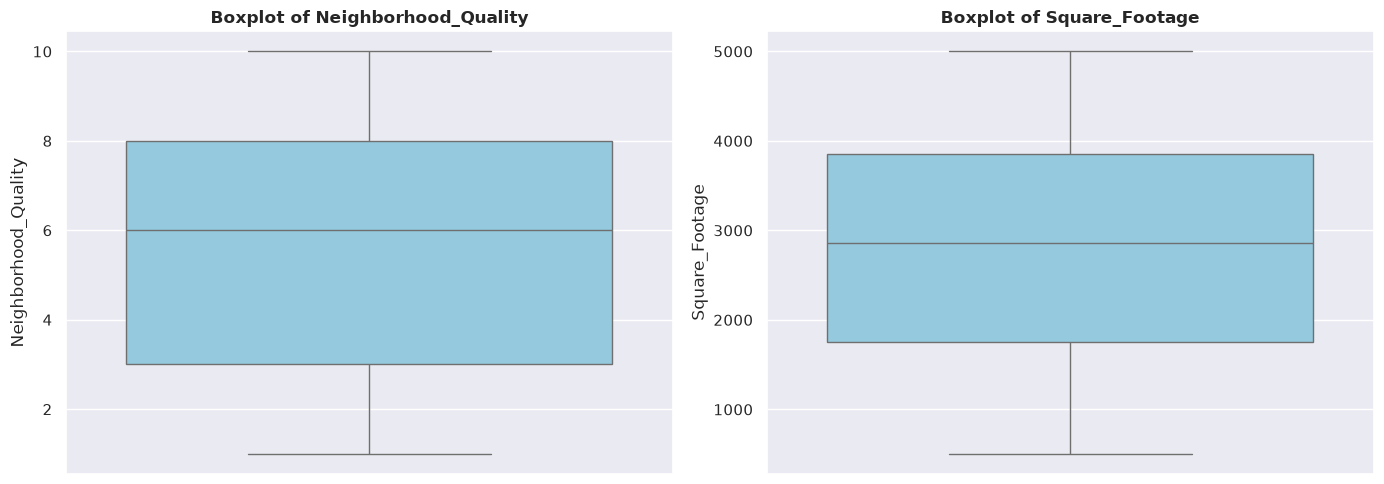

<Figure size 640x480 with 0 Axes>

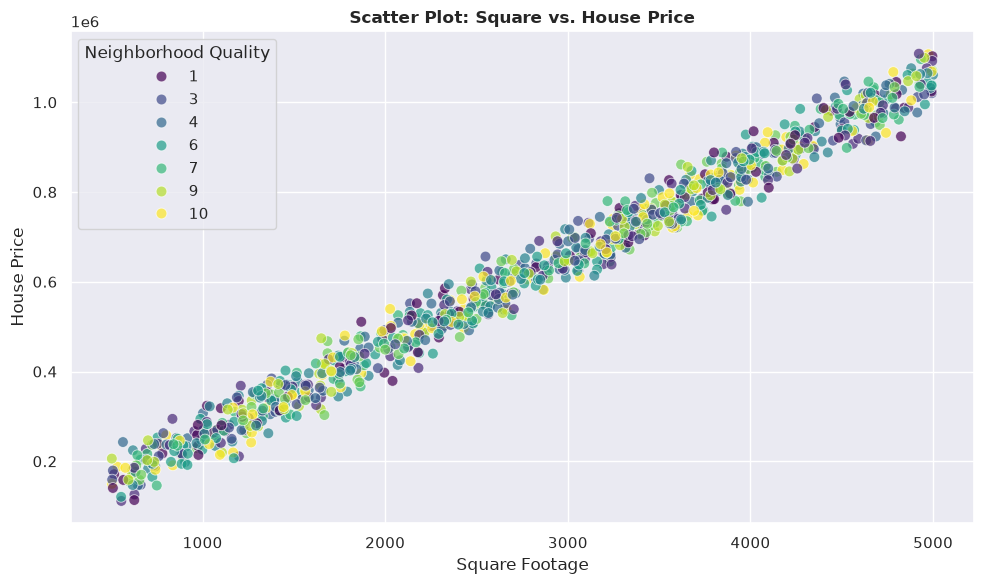

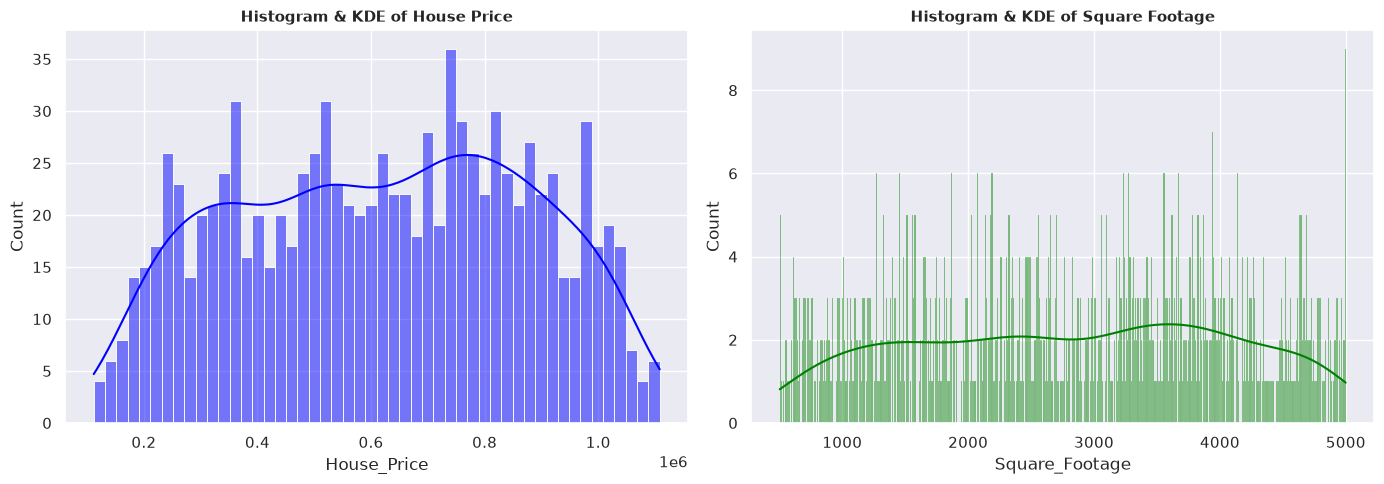

In [13]:
features_to_check = ["Square_Footage", "Lot_Size", "House_Price", "Year_Built"]

X = df.drop(columns=["House_Price"])
y = df["House_Price"]

# IQR (Interquartile Range)

for col in features_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    low = df[col] < lower_bound
    high = df[col] > upper_bound
    outliers_count = (low | high).sum()
    print(
        f"{col}: {outliers_count} outliers found (Bounds: {lower_bound} to {upper_bound})"
    )


#  Boxplots & Histplot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Neighborhood_Quality
sns.boxplot(data=df, y="Neighborhood_Quality", ax=axes[0], color="skyblue")
axes[0].set_title("Boxplot of Neighborhood_Quality", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Neighborhood_Quality")

# Square_Footage
sns.boxplot(data=df, y="Square_Footage", ax=axes[1], color="skyblue")
axes[1].set_title("Boxplot of Square_Footage", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Square_Footage")

plt.tight_layout()
plt.show()

sns.histplot(df["Square_Footage"], kde=True, ax=axes[1], color="green", bins=500)
axes[1].set_title("Histogram & KDE of Square Footage", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 6))

# Scatterplot Square Footage vs House Price

sns.scatterplot(
    data=df,
    x="Square_Footage",
    y="House_Price",
    hue="Neighborhood_Quality",
    palette="viridis",
    alpha=0.7,
    s=60,
)

plt.title("Scatter Plot: Square vs. House Price", fontsize=12, fontweight="bold")
plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.legend(title="Neighborhood Quality")
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with KDE curve
sns.histplot(df["House_Price"], kde=True, ax=axes[0], color="blue", bins=50)
axes[0].set_title("Histogram & KDE of House Price", fontsize=11, fontweight="bold")

sns.histplot(df["Square_Footage"], kde=True, ax=axes[1], color="green", bins=500)
axes[1].set_title("Histogram & KDE of Square Footage", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

In [ ]:
# Question 2

# Drop if more than 50% missing values
df = df.dropna(thresh=df.shape[0] / 2, axis=1)

target_col = "House_Price"
X = df.drop(columns=[target_col])
y = df[target_col]

categorical_cols = [
    "Num_Bedrooms",
    "Num_Bathrooms",
    "Garage_Size",
    "Neighborhood_Quality",
]
numerical_cols = [
    "Square_Footage",
    "Year_Built",
    "Lot_Size",
]

# Impute
num_imputer = SimpleImputer(strategy="mean")
X[numerical_cols] = num_imputer.fit_transform(X[numerical_cols])

cat_imputer = SimpleImputer(strategy="most_frequent")
X[categorical_cols] = cat_imputer.fit_transform(X[categorical_cols])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

# X_train,X_test

X_train shape: (800, 7)
X_test shape: (200, 7)


---

## Question 3 (20 Marks)

Implement **Simple Linear Regression** using **only NumPy** (no Scikit-Learn allowed):

- Compute slope (`m`) and intercept (`c`) using the Batch Gradient Descent
- Predict values for the test set
- Print the learned `m` and `c` values

Use `Square_Footage` as feature (X) and `House_Price` as target (y).


Iteration 0: Cost 17.9730, w: 0.2055, b: 0.0619
Iteration 1000: Cost 0.0564, w: 2.0018, b: 0.5548
Iteration 2000: Cost 0.0564, w: 2.0047, b: 0.5450
Iteration 3000: Cost 0.0563, w: 2.0054, b: 0.5429
Iteration 4000: Cost 0.0563, w: 2.0055, b: 0.5424
Iteration 5000: Cost 0.0563, w: 2.0056, b: 0.5423
Iteration 6000: Cost 0.0563, w: 2.0056, b: 0.5423
Iteration 7000: Cost 0.0563, w: 2.0056, b: 0.5423
Iteration 8000: Cost 0.0563, w: 2.0056, b: 0.5423
Iteration 9000: Cost 0.0563, w: 2.0056, b: 0.5423

Learned slope (m): 200.55687642978515
Learned intercept (c): 54229.06005610601

Actual House Prices:
[ 901000.48823382  494537.5115455   949404.20066573 1040389.04813578
  794010.01673364  724033.56045713  998439.23711398  909713.4350007
  792681.51842008  947490.77747782  774150.04681239  654466.94540868
  217462.44505709 1034380.20416167  530476.12327498  194353.73613998
  441315.08847494  354744.63059531  755402.37269125  348893.55395287
  763645.6101594   475767.3504504   676108.85120969  887

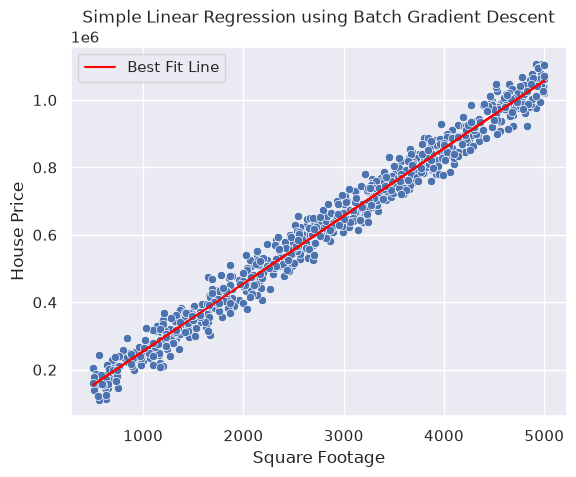

In [49]:
# Question 3

# Select feature and target
X = df["Square_Footage"]
y = df["House_Price"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale data for stable gradient descent
X_train = X_train / 1000
X_test = X_test / 1000
y_train = y_train / 100000


def make_prediction(X, w, b):
    """Calculates the model output: f(x) = wx + b"""
    m = X.shape[0]
    pred_list = np.zeros((m,))

    for i in range(m):
        pred_list[i] = w * X[i] + b

    return pred_list


def compute_cost(X, y, w, b):
    """Calculates the cost"""
    m = X.shape[0]
    cost = 0.0

    for i in range(m):
        prediction = w * X[i] + b
        error = prediction - y[i]
        cost = cost + error**2

    cost = cost / (2 * m)

    return cost


def calculate_gradient(X, y, w, b):
    """Computes the gradient for w and b"""
    m = X.shape[0]
    dj_dw = 0.0
    dj_db = 0.0

    for i in range(m):
        prediction = w * X[i] + b
        error = prediction - y[i]

        dj_dw = dj_dw + error * X[i]
        dj_db = dj_db + error

    return dj_dw / m, dj_db / m


def gradient_descent(X, y, w_input, b_input, max_iter, alpha=0.01):
    """Tunes w and b using Batch Gradient Descent"""
    w = w_input
    b = b_input
    cost_memo = []
    iteration = []

    for i in range(max_iter):
        # Calculate gradients using all training examples
        dj_dw, dj_db = calculate_gradient(X, y, w, b)

        # Update parameters
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Track cost
        cost = compute_cost(X, y, w, b)
        cost_memo.append(cost)
        iteration.append(i)

        if i % 1000 == 0:
            print(f"Iteration {i}: Cost {cost:.4f}, " f"w: {w:.4f}, b: {b:.4f}")

    return w, b, cost_memo, iteration


# Run Batch Gradient Descent
w_final, b_final, cost_memo, iter_list = gradient_descent(
    X_train, y_train, w_input=0, b_input=0, max_iter=10000, alpha=0.01
)

# Convert parameters back to original units
m_final = w_final * 100
c_final = b_final * 100000

print("\nLearned slope (m):", m_final)
print("Learned intercept (c):", c_final)

# Predict values for the test set
test_predictions = make_prediction(X_test, w_final, b_final)
test_predictions = test_predictions * 100000

print("\nActual House Prices:")
print(y_test)

print("\nPredicted House Prices:")
print(test_predictions)

# Calculate test Mean Squared Error
mse = np.mean((y_test - test_predictions) ** 2)
print("\nTest MSE:", mse)

# Plot training data and regression line
train_predictions = make_prediction(X_train, w_final, b_final)

sns.scatterplot(x=X_train * 1000, y=y_train * 100000)
plt.plot(X_train * 1000, train_predictions * 100000, color="red", label="Best Fit Line")

plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.title("Simple Linear Regression using Batch Gradient Descent")
plt.legend()
plt.show()

---

## Question 4 (10 Marks)

Build a **ColumnTransformer** that applies:

- `StandardScaler` on numerical columns: `Square_Footage`, `Num_Bedrooms`, `Num_Bathrooms`
- `OneHotEncoder` on categorical column: `Neighborhood_Quality`


In [16]:
# Question 4

## Question 5 (20 Marks)

Build a complete **Pipeline** using Scikit-Learn that includes:

- The `ColumnTransformer`
- `SGDRegressor` as the final estimator
- Train the pipeline and evaluate using RMSE and R² score
- Print predicted vs actual values for the first 10 test samples


In [17]:
# Question 5

---

## Question 6 (20 Marks)

Implement **Multiple Linear Regression** using **Scikit-Learn**:

- The `ColumnTransformer`
- `LinearRegression` as the final estimator
- Train the pipeline and evaluate using RMSE and R² score
- Print predicted vs actual values for the first 10 test samples


In [18]:
# Question 6

---

## Question 7 (10 Marks) (You have to explore the topic and use the equation via Numpy)

### Dont use LLMs , You can use Documentation

Implement **Multiple Linear Regression** using **only NumPy**:

- Pick random 100 datas from the dataset
- Use the Normal Equation: `θ = (XᵀX)⁻¹ Xᵀy`
- Use `Square_Footage`, `Num_Bedrooms`, and `Num_Bathrooms` as features
- Print the learned coefficients (θ values)


In [19]:
# Question 7